<div style="background: linear-gradient(135deg, #003366 0%, #0055a5 100%); border-radius: 12px; padding: 18px 26px; display: flex; align-items: center; gap: 24px; box-shadow: 0 4px 12px rgba(0,0,0,0.2);">
    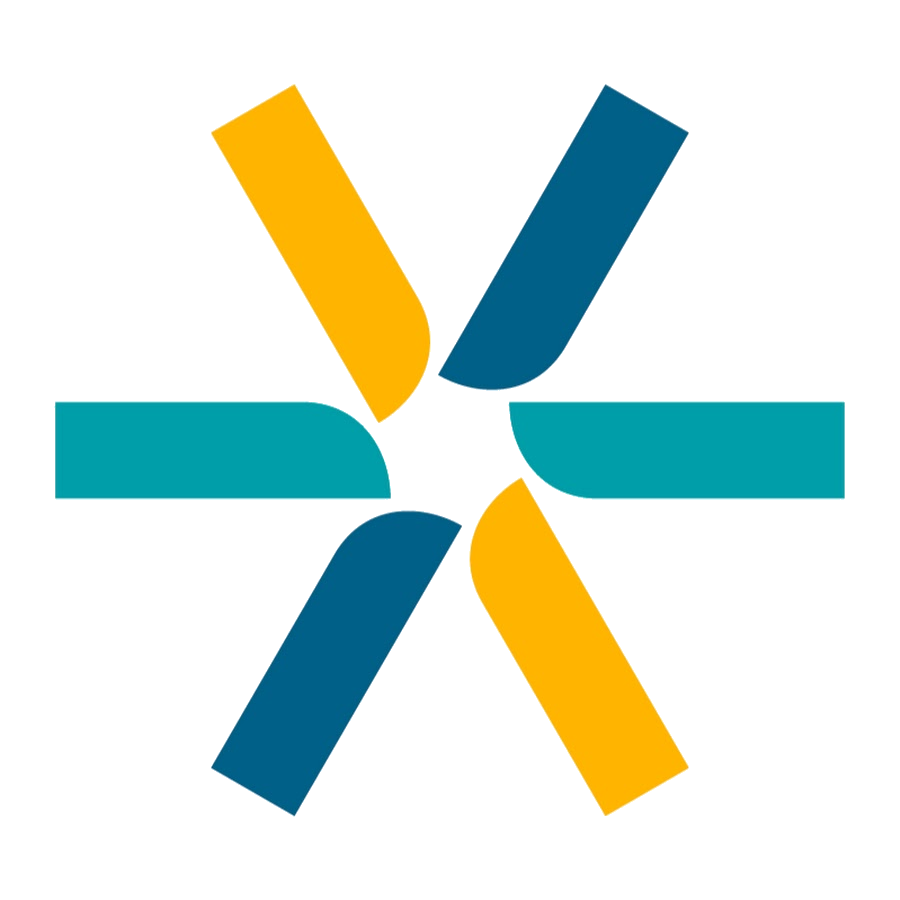
    <div>
        <h1 style="margin: 0; color: #ffffff; font-size: 1.45em; letter-spacing: 0.5px;">Aprendizaje Automático y Grandes Datos</h1>
        <h2 style="margin: 6px 0 2px 0; color: #cce4ff; font-size: 1.15em; font-weight: normal;">Regresión logística y softmax · demanda eléctrica (CAMMESA)</h2>
        <h3 style="margin: 0 0 8px 0; color: #a8d0f5; font-size: 1em; font-weight: normal;">Unidad 6 · Modelos lineales de clasificación</h3>
        <span style="background: #ffd700; color: #003366; font-weight: bold; font-size: 0.9em; padding: 3px 12px; border-radius: 20px;">⚡ Grupo 6 · Clase 32 sobre nuestro dataset</span>
    </div>
</div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Antes de empezar</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La pregunta</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">¿La demanda de este agente (agente + tarifa) va a <b>caer fuerte</b> el mes que viene, más de un 15 % respecto del mes anterior? Sí o no: una clasificación con dos clases. Y la pregunta de atrás: ¿con qué probabilidad? Para quien planifica el despacho, una caída brusca no anticipada es tan problemática como una suba.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los datos</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">El mismo <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">demanda-ltimos-aos.csv</code> de CAMMESA. Hasta ahora el objetivo era cuántos MWh; acá se transforma en una etiqueta 0/1 y las predictoras pasan a ser <b>relativas</b> (variaciones, volatilidad, tamaño en escala log), porque lo que importa ya no es el nivel sino el cambio.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se quiere resolver</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Ajustar la suma ponderada, pasarla por la logística para obtener una probabilidad, decidir con un umbral, y leer los coeficientes como cambios en las log-chances. Después, lo mismo con tres clases (softmax): baja, estable o sube.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se muestra</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas 8 secciones de la clase 32: los datos y el desbalance → dejarlos listos → la sentencia, la probabilidad, los coeficientes → la matriz, el umbral, el costo → variantes (iris del material, sin escalar, C y ℓ1, el gradiente a mano, el desbalance, softmax) → comparativo → usarlo → qué quedó.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cómo se decide</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Sobre la prueba (2019-07 a 2020-02), con varias métricas: precisión, exhaustividad, F1, AUC y log-loss, contra la línea de base que predice siempre la clase mayoritaria. El umbral alternativo se elige sobre una validación apartada del entrenamiento, no mirando la prueba.</td></tr></table></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué hay que saber de este problema antes de modelar</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Desbalance, como en la clase.</b> Solo ~17 % de las filas de entrenamiento son caídas fuertes, y en prueba menos (~13 %): decir «nunca cae» acierta más del 85 %. La exactitud no sirve y el umbral del 50 % va a resultar inútil.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Es un problema difícil.</b> En el gimnasio de la cátedra (bajas de clientes) dos columnas casi decidían. Acá no hay ninguna así: anticipar una caída de un agente a partir de su propia historia es genuinamente difícil, y el AUC va a quedar en ~0,66. Es el resultado honesto de un problema real, no un error. El método de la clase se aplica igual y se ve todo: el umbral, las razones de chances, el costo.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Corte temporal, otra vez.</b> No se parte con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">stratify</code> al azar: se entrena hasta 2019-06 y se prueba después. Por eso la proporción de caídas no es la misma en las dos partes, y eso también es parte del problema real.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">1 · Los datos y el desbalance</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Las predictoras, relativas</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">De cada serie se toman los rezagos 1, 2, 12 y 13 y se construyen ocho predictoras:</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code>: días del mes / días del mes anterior (la pista de la clase 31). <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_mes_ant</code>: cuánto cambió el mes pasado (lag1 / lag2 − 1). <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code>: ese cambio en valor absoluto, sin importar el signo. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_hace_un_anio</code>: cuánto cambió esta misma transición el año pasado (lag12 / lag13 − 1). <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">log_tamano</code>: log₁₀ de la demanda del mes anterior. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">mes_num</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_gran_usuario</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_residencial</code>.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El objetivo: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">cae_fuerte</code> = 1 si la demanda del mes es menor al 85 % de la del mes anterior. Las variaciones se recortan a [−1, 3] para que un agente que pasa de 1 a 500 MWh no domine todo.</p></div>

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
pd.set_option("display.width", 130)
np.set_printoptions(suppress=True, precision=3)

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
base_lags = demanda[["serie", "periodo", "demanda_MWh"]]
for k in [1, 2, 12, 13]:
    t = base_lags.copy(); t["periodo"] = t["periodo"] + k
    demanda = demanda.merge(t.rename(columns={"demanda_MWh": f"lag{k}"}), on=["serie", "periodo"], how="left")

datos = demanda[demanda["lag1"] > 0].copy()                    # hace falta un mes anterior positivo para hablar de "caída"
datos["ratio_dias"] = datos["periodo"].dt.days_in_month / (datos["periodo"] - 1).dt.days_in_month
datos["var_mes_ant"] = np.where(datos["lag2"] > 0, datos["lag1"] / datos["lag2"] - 1, np.nan)
datos["var_mes_ant"] = datos["var_mes_ant"].clip(-1, 3)
datos["volatilidad"] = datos["var_mes_ant"].abs()
datos["var_hace_un_anio"] = np.where((datos["lag13"] > 0) & (datos["lag12"] >= 0), datos["lag12"] / datos["lag13"] - 1, np.nan)
datos["var_hace_un_anio"] = datos["var_hace_un_anio"].clip(-1, 3)
datos["log_tamano"] = np.log10(datos["lag1"])
datos["mes_num"] = datos["periodo"].dt.month
datos["es_gran_usuario"] = (datos["categoria_demanda"] == "Gran Usuario").astype(int)
datos["es_residencial"] = (datos["categoria_tarifa"] == "Residencial").astype(int)
UMBRAL_CAIDA = 0.15
datos["cae_fuerte"] = (datos["demanda_MWh"] < (1 - UMBRAL_CAIDA) * datos["lag1"]).astype(int)
datos = datos.sort_values(["periodo", "serie"]).reset_index(drop=True)

PREDICTORAS = ["ratio_dias", "var_mes_ant", "volatilidad", "var_hace_un_anio", "log_tamano", "mes_num", "es_gran_usuario", "es_residencial"]
OBJETIVO = "cae_fuerte"
print(f"{len(datos)} filas · {len(PREDICTORAS)} predictoras · caídas fuertes: {datos[OBJETIVO].sum()} ({datos[OBJETIVO].mean() * 100:.1f} %)")
print("Faltantes (%):", (datos[PREDICTORAS].isna().mean() * 100).round(1).to_dict())
datos[PREDICTORAS + [OBJETIVO]].describe().round(2).T

37397 filas · 8 predictoras · caídas fuertes: 6139 (16.4 %)
Faltantes (%): {'ratio_dias': 0.0, 'var_mes_ant': 4.6, 'volatilidad': 4.6, 'var_hace_un_anio': 46.7, 'log_tamano': 0.0, 'mes_num': 0.0, 'es_gran_usuario': 0.0, 'es_residencial': 0.0}


,count,mean,std,min,25%,50%,75%,max
ratio_dias,37397.0,1.00,0.05,0.9,0.97,1.00,1.03,1.11
var_mes_ant,35692.0,0.05,0.42,-1.0,-0.09,-0.00,0.10,3.00
volatilidad,35692.0,0.20,0.37,0.0,0.04,0.09,0.21,3.00
var_hace_un_anio,19930.0,0.05,0.39,-1.0,-0.08,0.00,0.09,3.00
log_tamano,37397.0,3.01,1.08,-3.0,2.55,3.13,3.66,6.20
mes_num,37397.0,6.41,3.44,1.0,3.00,6.00,9.00,12.00
es_gran_usuario,37397.0,0.47,0.50,0.0,0.00,0.00,1.00,1.00
es_residencial,37397.0,0.39,0.49,0.0,0.00,0.00,1.00,1.00
cae_fuerte,37397.0,0.16,0.37,0.0,0.00,0.00,0.00,1.00


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Cómo se distribuye cada columna según la clase</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Azul: no cae fuerte; rojo: cae fuerte. Las binarias y el mes, como proporción de caídas.</p></div>

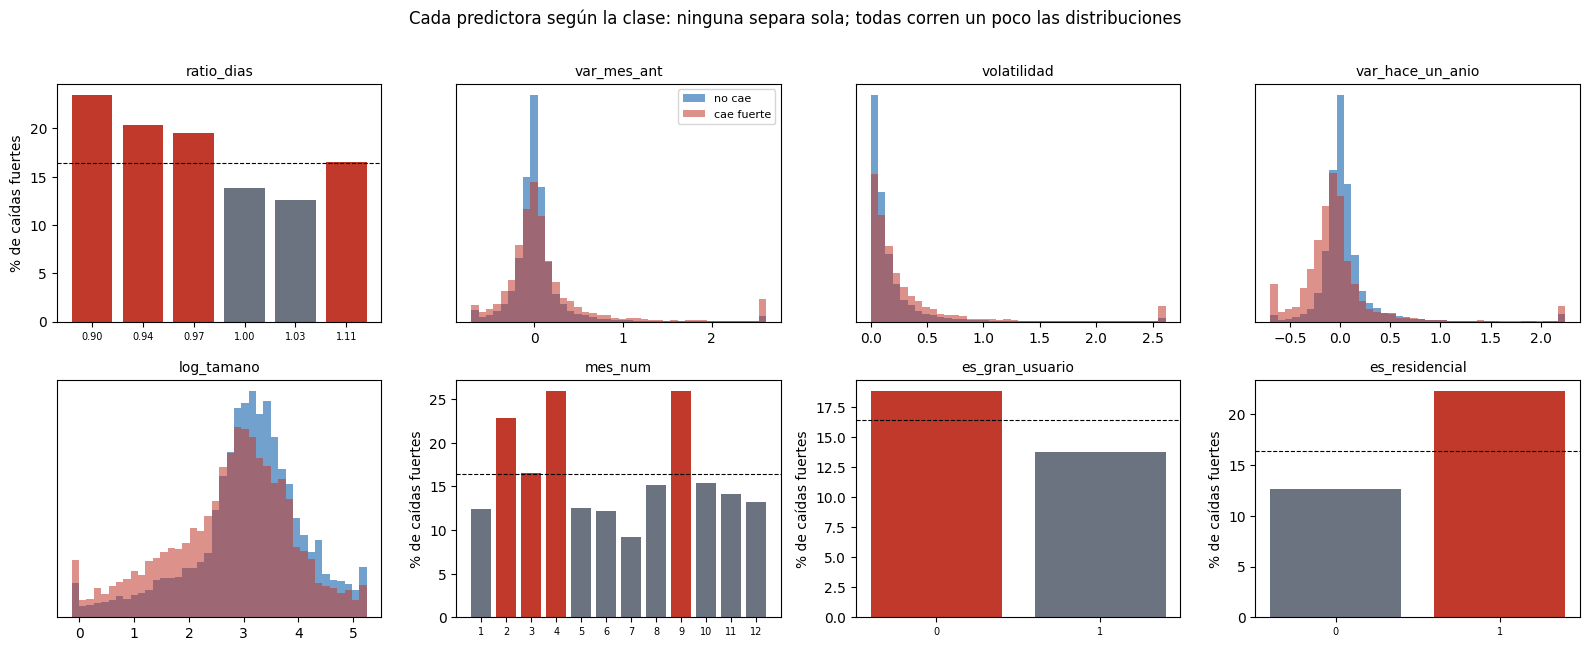

Correlación de cada predictora con la caída fuerte:
log_tamano         -0.112
var_hace_un_anio   -0.077
ratio_dias         -0.072
es_gran_usuario    -0.069
mes_num            -0.026
var_mes_ant         0.084
es_residencial      0.127
volatilidad         0.142


In [2]:
fig, ejes = plt.subplots(2, 4, figsize=(16, 6.4))
for ax, col in zip(ejes.ravel(), PREDICTORAS):
    if datos[col].nunique() <= 12:
        tasa = datos.groupby(col)[OBJETIVO].mean() * 100
        etiquetas = [f"{v:.2f}" if col == "ratio_dias" else str(int(v)) for v in tasa.index]
        ax.bar(etiquetas, tasa.values, color=[ROJO if v > datos[OBJETIVO].mean() * 100 else GRIS for v in tasa.values])
        ax.axhline(datos[OBJETIVO].mean() * 100, color="black", lw=0.8, ls="--"); ax.set_ylabel("% de caídas fuertes"); ax.set_title(col, fontsize=10)
        ax.tick_params(axis="x", labelsize=7)
    else:
        rango = datos[col].quantile([0.01, 0.99]).to_numpy()
        for clase, color, nombre in [(0, AZUL, "no cae"), (1, ROJO, "cae fuerte")]:
            ax.hist(datos.loc[datos[OBJETIVO] == clase, col].dropna().clip(*rango), bins=40, color=color, alpha=0.55, density=True, label=nombre)
        ax.set_title(col, fontsize=10); ax.set_yticks([])
ejes[0, 1].legend(fontsize=8)
fig.suptitle("Cada predictora según la clase: ninguna separa sola; todas corren un poco las distribuciones", y=1.01)
plt.tight_layout(); plt.show()
print("Correlación de cada predictora con la caída fuerte:")
print(datos[PREDICTORAS + [OBJETIVO]].corr()[OBJETIVO].drop(OBJETIVO).round(3).sort_values().to_string())

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Nada separa como las quejas de los clientes de la telefónica. Lo que sí aparece: en febrero (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code> = 0,90) hay muchas más caídas, porque es un mes más corto; los agentes chicos (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">log_tamano</code> bajo) y los más volátiles caen más seguido; y las tarifas residenciales también. Las correlaciones son todas de 0,1 o menos: cada columna aporta un poco. Ese es el escenario donde se juega la regresión logística, que suma muchas señales débiles.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">2 · Dejarlo listo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Partir por fecha, imputar, escalar, y la línea de base que engaña</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Corte temporal en 2019-06, como en las clases 29 y 31. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_hace_un_anio</code> falta en casi la mitad de las filas (no hay año anterior para 2017 ni para las tarifas recategorizadas), así que el flujo es imputar, escalar y modelo.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La línea de base es <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">DummyClassifier(strategy="most_frequent")</code>: predice siempre «no cae». <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">registrar()</code> guarda seis métricas sobre prueba.</p></div>

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss

CORTE = pd.Period("2019-06", freq="M")
ent_mask = datos["periodo"] <= CORTE
X_ent, X_pru = datos.loc[ent_mask, PREDICTORAS], datos.loc[~ent_mask, PREDICTORAS]
y_ent, y_pru = datos.loc[ent_mask, OBJETIVO], datos.loc[~ent_mask, OBJETIVO]
print(f"entrenamiento: {len(X_ent)} filas ({y_ent.mean() * 100:.1f} % caídas) · prueba: {len(X_pru)} ({y_pru.mean() * 100:.1f} % caídas)")

def preparado(modelo):
    """Imputar, escalar y recién entonces el modelo."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), modelo)

resultados = {}
def registrar(nombre, modelo, umbral=0.5, X_e=None, X_p=None):
    X_e = X_ent if X_e is None else X_e; X_p = X_pru if X_p is None else X_p
    t0 = time.perf_counter(); modelo.fit(X_e, y_ent); t = (time.perf_counter() - t0) * 1000
    prob = modelo.predict_proba(X_p)[:, 1]
    pred = (prob >= umbral).astype(int)
    resultados[nombre] = {"exactitud": accuracy_score(y_pru, pred), "precisión": precision_score(y_pru, pred, zero_division=0),
                          "exhaustividad": recall_score(y_pru, pred), "F1": f1_score(y_pru, pred), "AUC": roc_auc_score(y_pru, prob),
                          "log-loss": log_loss(y_pru, prob), "ajuste (ms)": t, "modelo": modelo}
    return modelo

base = registrar("línea de base (mayoritaria)", DummyClassifier(strategy="most_frequent"))
print(f"Línea de base: exactitud = {resultados['línea de base (mayoritaria)']['exactitud']:.3f} sin anticipar una sola caída. Esa exactitud es la trampa.")

entrenamiento: 31415 filas (17.1 % caídas) · prueba: 5982 (12.7 % caídas)
Línea de base: exactitud = 0.873 sin anticipar una sola caída. Esa exactitud es la trampa.


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">3 · El algoritmo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La sentencia de la diapositiva</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">LogisticRegression().fit(X, y)</code>, adentro del flujo. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict_proba</code> da dos columnas (p̂ de 0 y de 1, suman 1); <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict</code> compara con 0,5.</p></div>

In [4]:
from sklearn.linear_model import LogisticRegression

modelo = preparado(LogisticRegression())
modelo.fit(X_ent, y_ent)
primeros = X_pru.head()
tabla = primeros.copy()
tabla["p̂(no cae)"], tabla["p̂(cae fuerte)"] = modelo.predict_proba(primeros).round(3).T
tabla["predict"] = modelo.predict(primeros)
tabla["real"] = y_pru.head().values
tabla

,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,p̂(no cae),p̂(cae fuerte),predict,real
31415,1.033333,0.029428,0.029428,0.053738,3.090951,7,1,0,0.896,0.104,0,0
31416,1.033333,0.054989,0.054989,0.017103,3.082777,7,1,0,0.892,0.108,0,0
31417,1.033333,-0.332686,0.332686,-0.266401,2.441544,7,1,0,0.818,0.182,0,0
31418,1.033333,-0.286159,0.286159,-0.180852,2.593948,7,1,0,0.838,0.162,0,0
31419,1.033333,-0.060227,0.060227,0.061857,4.299507,7,1,0,0.906,0.094,0,0


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La suma, la logística y la probabilidad</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Puntaje t = θᵀx (las log-chances), σ(t) = 1 / (1 + e⁻ᵗ), p̂ = σ(t). Calculado a mano para toda la prueba.</p></div>

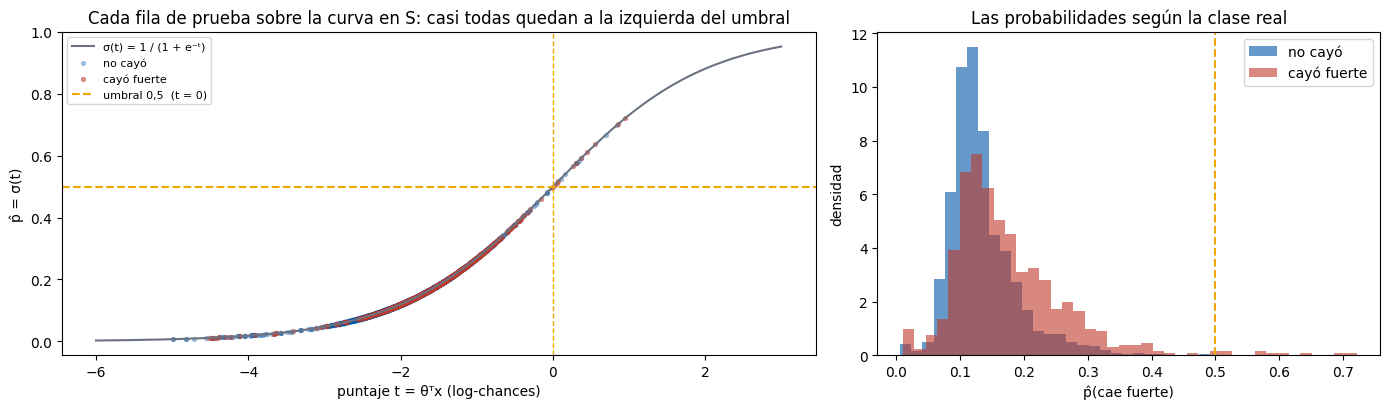

intercept_ = -1.67 → para la fila promedio p̂ = σ(-1.67) = 0.158
p̂ máxima en toda la prueba: 0.722 · filas con p̂ ≥ 0,5: 18 de 5982


In [5]:
logistica = modelo[-1]
X_pru_esc = modelo[:-1].transform(X_pru)                                  # lo que ve la logística: imputado y escalado
puntaje = logistica.intercept_[0] + X_pru_esc @ logistica.coef_[0]
def sigmoide(t): return 1 / (1 + np.exp(-t))
prob = sigmoide(puntaje)
assert np.allclose(prob, modelo.predict_proba(X_pru)[:, 1])

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [3, 2]})
ts = np.linspace(-6, 3, 300)
a.plot(ts, sigmoide(ts), color=GRIS, lw=1.5, label="σ(t) = 1 / (1 + e⁻ᵗ)")
a.scatter(puntaje[y_pru == 0], prob[y_pru == 0], s=8, alpha=0.3, color=AZUL, label="no cayó")
a.scatter(puntaje[y_pru == 1], prob[y_pru == 1], s=8, alpha=0.5, color=ROJO, label="cayó fuerte")
a.axhline(0.5, color=AMBAR, ls="--", lw=1.5, label="umbral 0,5  (t = 0)"); a.axvline(0, color=AMBAR, ls="--", lw=1)
a.set_xlabel("puntaje t = θᵀx (log-chances)"); a.set_ylabel("p̂ = σ(t)"); a.legend(fontsize=8, loc="upper left")
a.set_title("Cada fila de prueba sobre la curva en S: casi todas quedan a la izquierda del umbral")
b.hist(prob[y_pru == 0], bins=40, color=AZUL, alpha=0.6, density=True, label="no cayó"); b.hist(prob[y_pru == 1], bins=40, color=ROJO, alpha=0.6, density=True, label="cayó fuerte")
b.axvline(0.5, color=AMBAR, ls="--", lw=1.5); b.set_xlabel("p̂(cae fuerte)"); b.set_ylabel("densidad"); b.legend(); b.set_title("Las probabilidades según la clase real")
plt.tight_layout(); plt.show()
print(f"intercept_ = {logistica.intercept_[0]:.2f} → para la fila promedio p̂ = σ({logistica.intercept_[0]:.2f}) = {sigmoide(logistica.intercept_[0]):.3f}")
print(f"p̂ máxima en toda la prueba: {prob.max():.3f} · filas con p̂ ≥ 0,5: {(prob >= 0.5).sum()} de {len(prob)}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El modelo nunca está muy seguro: casi todas las probabilidades caen entre 0,05 y 0,40, y muy pocas pasan 0,5. Las de las filas que sí cayeron están corridas a la derecha, pero se superponen mucho con las otras. El modelo <b>ordena</b> algo (las caídas reciben en promedio más probabilidad), pero no separa. Ya se adivina lo que va a pasar con el umbral del 50 %.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Los coeficientes: log-chances por desvío, y la razón de chances</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con las columnas escaladas, cada coeficiente es cuánto suben las log-chances de una caída fuerte cuando esa columna sube un desvío; e^coef es la razón de chances.</p></div>

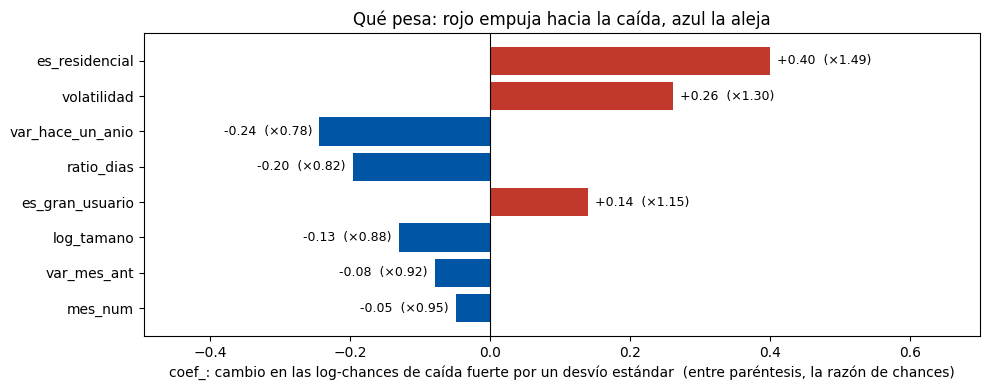

,coef_ (log-chances por desvío),razón de chances e^b,desvío de la columna
es_residencial,0.400,1.492,0.495
volatilidad,0.261,1.298,0.376
var_hace_un_anio,-0.244,0.784,0.263
ratio_dias,-0.196,0.822,0.052
es_gran_usuario,0.140,1.150,0.497
log_tamano,-0.130,0.878,1.091
var_mes_ant,-0.079,0.924,0.424
mes_num,-0.049,0.952,3.335


In [6]:
coefs = pd.DataFrame({"coef_ (log-chances por desvío)": logistica.coef_[0], "razón de chances e^b": np.exp(logistica.coef_[0]),
                      "desvío de la columna": modelo[1].scale_}, index=PREDICTORAS)
coefs = coefs.reindex(coefs["coef_ (log-chances por desvío)"].abs().sort_values(ascending=False).index)
fig, ax = plt.subplots(figsize=(10, 4))
v_ = coefs["coef_ (log-chances por desvío)"]
ax.barh(coefs.index, v_, color=[ROJO if v > 0 else AZUL for v in v_]); ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
ax.set_xlim(v_.min() - 0.25, v_.max() + 0.3)
for k, (v, rc) in enumerate(zip(v_, coefs["razón de chances e^b"])):
    ax.text(v + (0.01 if v > 0 else -0.01), k, f"{v:+.2f}  (×{rc:.2f})", va="center", ha="left" if v > 0 else "right", fontsize=9)
ax.set_xlabel("coef_: cambio en las log-chances de caída fuerte por un desvío estándar  (entre paréntesis, la razón de chances)")
ax.set_title("Qué pesa: rojo empuja hacia la caída, azul la aleja")
plt.tight_layout(); plt.show()
coefs.round(3)

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Cómo se leen</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Ser tarifa residencial multiplica las chances de una caída fuerte por ~1,5; un desvío más de volatilidad, por ~1,3. Un mes más largo que el anterior (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code> alto) y haber subido en esa misma transición el año pasado (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_hace_un_anio</code>) las bajan. Los agentes más grandes caen menos. Todo tiene sentido físico, y todas las razones de chances están entre ~0,8 y ~1,5: señales débiles.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Ojo con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_mes_ant</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code>: una es el valor absoluto de la otra y están correlacionadas. Su reparto es inestable, igual que segundos y llamadas en el ejemplo de la cátedra. Lo que dicen juntas: una variación grande el mes pasado, en cualquier dirección, aumenta el riesgo, y algo más si fue para abajo (las caídas tienden a seguir).</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Un caso para mirar: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_gran_usuario</code>. En crudo, los grandes usuarios caen <b>menos</b> (sección 1), pero el coeficiente sale positivo. No es contradicción: es el «con las demás quietas». Las tarifas residenciales, que caen mucho, son todas de distribuidoras; comparando a igual tarifa y tamaño, un gran usuario cae algo más.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Y lo de siempre: es asociación en esta muestra, no causa.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Cómo se arma la probabilidad de una fila</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Una fila de prueba que sí cayó, desarmada: sesgo + aportes = puntaje, en log-chances; la logística lo convierte en probabilidad.</p></div>

APARPPNA | GUMAS/AUTOGENERADORES · 2020-01: real = cayó fuerte · puntaje = 0.95 · p̂ = 0.722


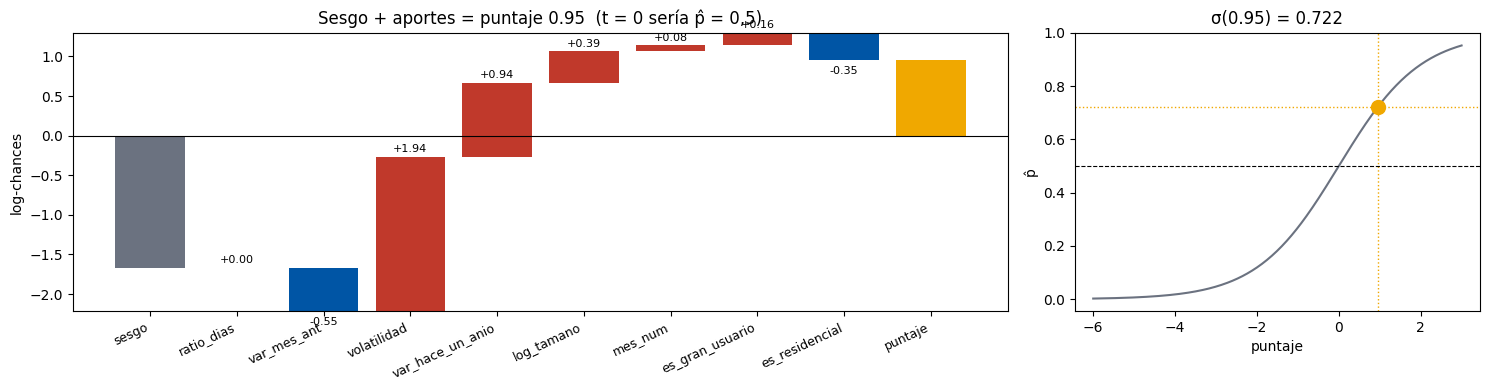

In [7]:
i = int(np.argsort(np.where(y_pru.to_numpy() == 1, prob, -1))[-1])        # la caída real a la que el modelo le dio más probabilidad
z = X_pru_esc[i]
aportes = pd.Series(logistica.coef_[0] * z, index=PREDICTORAS)
t_i = logistica.intercept_[0] + aportes.sum()
print(f"{datos.loc[X_pru.index[i], 'serie']} · {datos.loc[X_pru.index[i], 'periodo']}: real = {'cayó fuerte' if y_pru.iloc[i] == 1 else 'no cayó'} · puntaje = {t_i:.2f} · p̂ = {sigmoide(t_i):.3f}")

fig, (a, b) = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1.3]})
etiquetas = ["sesgo"] + PREDICTORAS + ["puntaje"]; acum = logistica.intercept_[0]
a.bar(0, logistica.intercept_[0], color=GRIS)
for k, v in enumerate(aportes, start=1):
    a.bar(k, v, bottom=acum, color=ROJO if v >= 0 else AZUL); a.text(k, acum + v + (0.06 if v >= 0 else -0.18), f"{v:+.2f}", ha="center", fontsize=8); acum += v
a.bar(len(etiquetas) - 1, t_i, color=AMBAR); a.axhline(0, color="black", lw=0.8)
a.set_xticks(range(len(etiquetas))); a.set_xticklabels(etiquetas, rotation=25, ha="right", fontsize=9); a.set_ylabel("log-chances")
a.set_title(f"Sesgo + aportes = puntaje {t_i:.2f}  (t = 0 sería p̂ = 0,5)")
b.plot(ts, sigmoide(ts), color=GRIS); b.plot([t_i], [sigmoide(t_i)], marker="o", ms=10, color=AMBAR)
b.axhline(sigmoide(t_i), color=AMBAR, ls=":", lw=1); b.axvline(t_i, color=AMBAR, ls=":", lw=1); b.axhline(0.5, color="black", ls="--", lw=0.8)
b.set_xlabel("puntaje"); b.set_ylabel("p̂"); b.set_title(f"σ({t_i:.2f}) = {sigmoide(t_i):.3f}")
plt.tight_layout(); plt.show()

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">4 · El resultado: la matriz, el umbral y el costo</h2></div>

In [8]:
registrar("logística (escalada, C=1)", modelo)
pd.DataFrame({k: {m: v[m] for m in ["exactitud", "precisión", "exhaustividad", "F1", "AUC", "log-loss"]} for k, v in resultados.items()}).round(3)

,línea de base (mayoritaria),"logística (escalada, C=1)"
exactitud,0.873,0.873
precisión,0.000,0.556
exhaustividad,0.000,0.013
F1,0.000,0.026
AUC,0.500,0.663
log-loss,4.573,0.365


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">El umbral se elige, y no mirando la prueba</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con 0,5 la logística casi no marca ninguna caída. Para elegir otro umbral sin hacer trampa, se aparta el último 20 % del entrenamiento como validación, se ajusta con el resto, y se busca el umbral que maximiza F1 <b>en esa validación</b>. Recién después se lo aplica a la prueba.</p></div>

In [9]:
corte_v = int(len(X_ent) * 0.8)                                  # los datos están ordenados por período: el último tramo es validación
m_val = preparado(LogisticRegression()).fit(X_ent.iloc[:corte_v], y_ent.iloc[:corte_v])
p_val = m_val.predict_proba(X_ent.iloc[corte_v:])[:, 1]
candidatos = np.round(np.arange(0.05, 0.60, 0.01), 2)
f1_val = [f1_score(y_ent.iloc[corte_v:], p_val >= u) for u in candidatos]
UMBRAL_ALT = float(candidatos[int(np.argmax(f1_val))])
print(f"Umbral elegido en validación: {UMBRAL_ALT} (F1 de validación {max(f1_val):.3f})")

Umbral elegido en validación: 0.15 (F1 de validación 0.257)


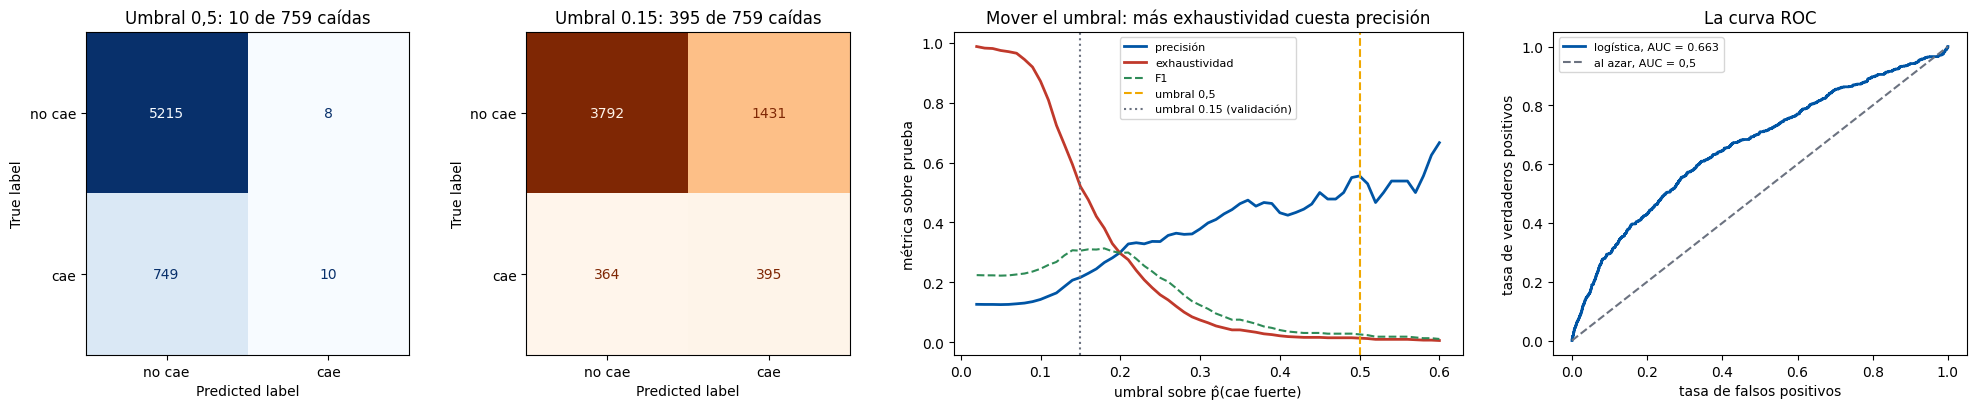

umbral 0.5: precisión 0.556 · exhaustividad 0.013 · F1 0.026 · filas marcadas: 18 de 5982 (caídas reales: 759)
umbral 0.15: precisión 0.216 · exhaustividad 0.520 · F1 0.306 · filas marcadas: 1826 de 5982 (caídas reales: 759)


In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve

fig, (a, a2, b, cc) = plt.subplots(1, 4, figsize=(20, 4.2), gridspec_kw={"width_ratios": [1.1, 1.1, 1.6, 1.3]})
ConfusionMatrixDisplay(confusion_matrix(y_pru, prob >= 0.5), display_labels=["no cae", "cae"]).plot(ax=a, colorbar=False, cmap="Blues")
a.set_title(f"Umbral 0,5: {((prob >= 0.5) & (y_pru == 1)).sum()} de {y_pru.sum()} caídas")
ConfusionMatrixDisplay(confusion_matrix(y_pru, prob >= UMBRAL_ALT), display_labels=["no cae", "cae"]).plot(ax=a2, colorbar=False, cmap="Oranges")
a2.set_title(f"Umbral {UMBRAL_ALT}: {((prob >= UMBRAL_ALT) & (y_pru == 1)).sum()} de {y_pru.sum()} caídas")
umbrales = np.linspace(0.02, 0.6, 59)
b.plot(umbrales, [precision_score(y_pru, prob >= u, zero_division=0) for u in umbrales], color=AZUL, lw=2, label="precisión")
b.plot(umbrales, [recall_score(y_pru, prob >= u) for u in umbrales], color=ROJO, lw=2, label="exhaustividad")
b.plot(umbrales, [f1_score(y_pru, prob >= u) for u in umbrales], color=VERDE, lw=1.5, ls="--", label="F1")
b.axvline(0.5, color=AMBAR, ls="--", lw=1.5, label="umbral 0,5"); b.axvline(UMBRAL_ALT, color=GRIS, ls=":", lw=1.5, label=f"umbral {UMBRAL_ALT} (validación)")
b.set_xlabel("umbral sobre p̂(cae fuerte)"); b.set_ylabel("métrica sobre prueba"); b.legend(fontsize=8); b.set_title("Mover el umbral: más exhaustividad cuesta precisión")
fpr, tpr, _ = roc_curve(y_pru, prob)
cc.plot(fpr, tpr, color=AZUL, lw=2, label=f"logística, AUC = {roc_auc_score(y_pru, prob):.3f}"); cc.plot([0, 1], [0, 1], color=GRIS, ls="--", label="al azar, AUC = 0,5")
cc.set_xlabel("tasa de falsos positivos"); cc.set_ylabel("tasa de verdaderos positivos"); cc.legend(fontsize=8); cc.set_title("La curva ROC")
plt.tight_layout(); plt.show()
for u in [0.5, UMBRAL_ALT]:
    pred_u = (prob >= u).astype(int)
    print(f"umbral {u}: precisión {precision_score(y_pru, pred_u, zero_division=0):.3f} · exhaustividad {recall_score(y_pru, pred_u):.3f} · F1 {f1_score(y_pru, pred_u):.3f} · filas marcadas: {pred_u.sum()} de {len(pred_u)} (caídas reales: {y_pru.sum()})")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con 0,5 el modelo es la línea de base con otro nombre: no anticipa casi ninguna caída. Con el umbral elegido en validación atrapa cerca de la mitad de las caídas, pero de cada cinco alarmas, una sola es real. La curva ROC queda por encima de la diagonal, sin acercarse a la esquina: el AUC de ~0,66 dice que si se toma una fila que cayó y una que no, el modelo le da más probabilidad a la que cayó dos de cada tres veces.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Si sirve o no depende del problema. Para un despacho que prefiere revisar diez agentes de más antes que no ver una caída, un umbral bajo con mucha exhaustividad tiene sentido. El umbral lo decide el costo de cada error, no el algoritmo.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">El costo de equivocarse: log-loss</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">−log(p̂) si cayó, −log(1 − p̂) si no. Comparado con la línea de base y con la «probabilidad constante» (la tasa de caídas del entrenamiento), que es la referencia justa para un log-loss.</p></div>

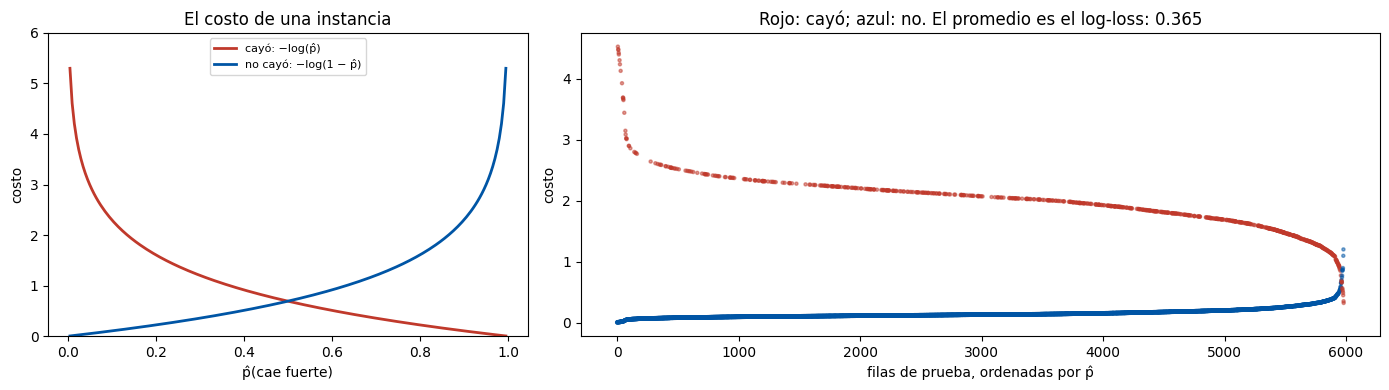

log-loss del modelo = 0.365  ·  probabilidad constante 0.171 = 0.388  ·  línea de base (p̂ = 0 siempre) = 4.57


In [11]:
costo = np.where(y_pru == 1, -np.log(prob), -np.log(1 - prob))
p_const = y_ent.mean()
ll_const = log_loss(y_pru, np.full(len(y_pru), p_const))
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.2, 2]})
ps = np.linspace(0.005, 0.995, 200)
a.plot(ps, -np.log(ps), color=ROJO, lw=2, label="cayó: −log(p̂)"); a.plot(ps, -np.log(1 - ps), color=AZUL, lw=2, label="no cayó: −log(1 − p̂)")
a.set_xlabel("p̂(cae fuerte)"); a.set_ylabel("costo"); a.set_ylim(0, 6); a.legend(fontsize=8); a.set_title("El costo de una instancia")
orden = np.argsort(prob)
b.scatter(np.arange(len(prob)), costo[orden], c=[ROJO if v == 1 else AZUL for v in y_pru.to_numpy()[orden]], s=5, alpha=0.5)
b.set_xlabel("filas de prueba, ordenadas por p̂"); b.set_ylabel("costo"); b.set_title(f"Rojo: cayó; azul: no. El promedio es el log-loss: {costo.mean():.3f}")
plt.tight_layout(); plt.show()
print(f"log-loss del modelo = {costo.mean():.3f}  ·  probabilidad constante {p_const:.3f} = {ll_const:.3f}  ·  línea de base (p̂ = 0 siempre) = {resultados['línea de base (mayoritaria)']['log-loss']:.2f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El costo de las caídas reales (rojo) es alto en casi todas: el modelo les da poca probabilidad y paga −log de un número chico. La comparación justa no es con la línea de base (que da probabilidad cero y explota), sino con decir siempre «17 % de chances»: el modelo mejora un poco ese log-loss. La mejora existe y es modesta, coherente con el AUC.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">5 · Las variantes</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.1 · El ejemplo del material: iris, el ancho del pétalo, y la frontera</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las figuras de la diapositiva salen de iris, así que esta celda se deja igual que la de la cátedra. Los datos vienen con la biblioteca.</p></div>

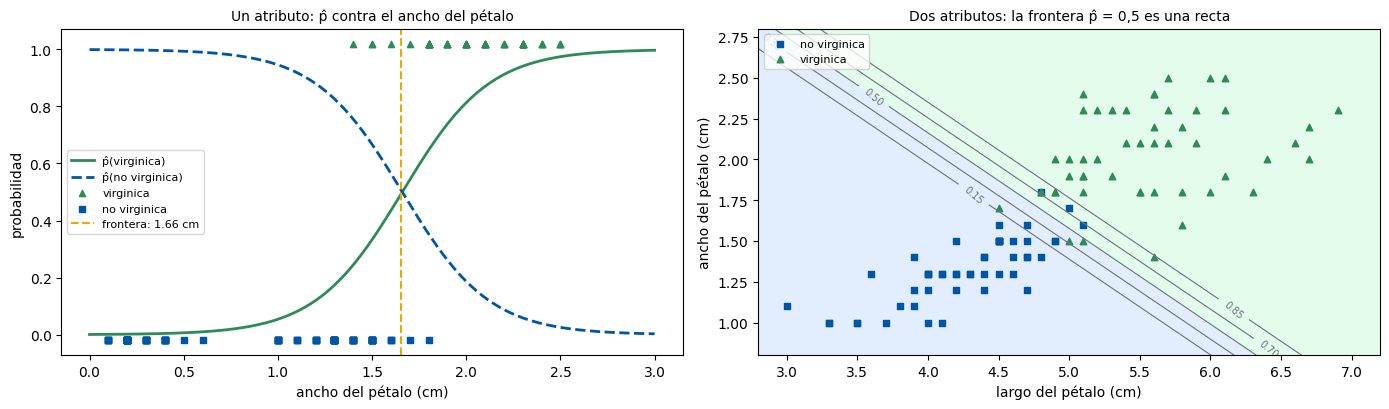

Una flor de 1,7 cm de ancho: predict = 1 · predict_proba = [0.457 0.543]


In [12]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
flores = iris.frame
flores["virginica"] = (flores["target"] == 2).astype(int)
ancho = flores[["petal width (cm)"]]
log_iris = LogisticRegression().fit(ancho, flores["virginica"])
anchos = pd.DataFrame({"petal width (cm)": np.linspace(0, 3, 300)})
p_virg = log_iris.predict_proba(anchos)[:, 1]
frontera = anchos.iloc[np.argmin(np.abs(p_virg - 0.5)), 0]

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.2))
a.plot(anchos, p_virg, color=VERDE, lw=2, label="p̂(virginica)"); a.plot(anchos, 1 - p_virg, color=AZUL, lw=2, ls="--", label="p̂(no virginica)")
a.scatter(ancho[flores["virginica"] == 1], np.ones(50) * 1.02, marker="^", color=VERDE, s=20, label="virginica"); a.scatter(ancho[flores["virginica"] == 0], np.zeros(100) - 0.02, marker="s", color=AZUL, s=20, label="no virginica")
a.axvline(frontera, color=AMBAR, ls="--", lw=1.5, label=f"frontera: {frontera:.2f} cm"); a.set_xlabel("ancho del pétalo (cm)"); a.set_ylabel("probabilidad"); a.legend(fontsize=8, loc="center left")
a.set_title("Un atributo: p̂ contra el ancho del pétalo", fontsize=10)
dos = flores[["petal length (cm)", "petal width (cm)"]]
log_iris2 = LogisticRegression(C=100).fit(dos, flores["virginica"])
g1, g2 = np.meshgrid(np.linspace(2.8, 7.2, 200), np.linspace(0.8, 2.8, 200))
pp = log_iris2.predict_proba(pd.DataFrame({"petal length (cm)": g1.ravel(), "petal width (cm)": g2.ravel()}))[:, 1].reshape(g1.shape)
b.contourf(g1, g2, pp, levels=[0, 0.5, 1], colors=["#dbeafe", "#dcfce7"], alpha=0.8)
cs = b.contour(g1, g2, pp, levels=[0.15, 0.3, 0.5, 0.7, 0.85], colors=[GRIS], linewidths=0.8); b.clabel(cs, fmt="%.2f", fontsize=7)
b.scatter(dos.loc[flores["virginica"] == 0, "petal length (cm)"], dos.loc[flores["virginica"] == 0, "petal width (cm)"], marker="s", color=AZUL, s=22, label="no virginica")
b.scatter(dos.loc[flores["virginica"] == 1, "petal length (cm)"], dos.loc[flores["virginica"] == 1, "petal width (cm)"], marker="^", color=VERDE, s=22, label="virginica")
b.set_xlim(2.8, 7.2); b.set_ylim(0.8, 2.8); b.set_xlabel("largo del pétalo (cm)"); b.set_ylabel("ancho del pétalo (cm)"); b.legend(fontsize=8, loc="upper left")
b.set_title("Dos atributos: la frontera p̂ = 0,5 es una recta", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Una flor de 1,7 cm de ancho: predict = {log_iris.predict(pd.DataFrame({'petal width (cm)': [1.7]}))[0]} · predict_proba = {log_iris.predict_proba(pd.DataFrame({'petal width (cm)': [1.7]}))[0].round(3)}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.2 · Sin escalar</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Acá hay una diferencia con la clase que vale la pena mostrar. Nuestras predictoras ya son relativas (variaciones, logaritmo, días): todas viven en escalas parecidas. Por eso, sin escalar, el resolvedor converge igual. Para ver el problema de la clase, se reemplaza <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">log_tamano</code> por la demanda del mes anterior <b>en MWh</b> (de 0 a 1,5 millones) y se repite.</p></div>

In [13]:
PRED_MWH = [c if c != "log_tamano" else "lag1" for c in PREDICTORAS]
X_ent_mwh, X_pru_mwh = datos.loc[ent_mask, PRED_MWH], datos.loc[~ent_mask, PRED_MWH]
filas = []
for nombre, flujo_, Xe, Xp in [("relativas, sin escalar", make_pipeline(SimpleImputer(strategy="median"), LogisticRegression()), X_ent, X_pru),
                               ("con lag1 en MWh, sin escalar", make_pipeline(SimpleImputer(strategy="median"), LogisticRegression()), X_ent_mwh, X_pru_mwh),
                               ("con lag1 en MWh, sin escalar, 5000 iter.", make_pipeline(SimpleImputer(strategy="median"), LogisticRegression(max_iter=5000)), X_ent_mwh, X_pru_mwh),
                               ("relativas, escaladas", preparado(LogisticRegression()), X_ent, X_pru)]:
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        registrar(f"logística {nombre}", flujo_, X_e=Xe, X_p=Xp)
    r = resultados[f"logística {nombre}"]
    filas.append({"variante": nombre, "iteraciones": int(flujo_[-1].n_iter_[0]), "aviso de convergencia": any("converge" in str(a.message).lower() for a in avisos),
                  "AUC": r["AUC"], "log-loss": r["log-loss"]})
pd.DataFrame(filas).set_index("variante").round(3)

,iteraciones,aviso de convergencia,AUC,log-loss
variante,,,,
"relativas, sin escalar",61,False,0.662,0.365
"con lag1 en MWh, sin escalar",100,True,0.556,0.380
"con lag1 en MWh, sin escalar, 5000 iter.",1109,False,0.658,0.366
"relativas, escaladas",11,False,0.663,0.365


<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con las predictoras relativas, sin escalar converge en pocas iteraciones más que escaladas. Con una columna en MWh, lbfgs se queda sin iteraciones y avisa, y el modelo que entrega está a medio camino: el AUC se desploma. Con 5000 iteraciones termina llegando, pero necesita cientos de veces más pasos que escalado. Por eso en este cuaderno el tamaño entra como logaritmo, y por eso se escala igual: escalar no cuesta nada y protege contra columnas así.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.3 · Regularizada por defecto: C, al revés que α</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">C chico = mucho freno. Se barre C de 0,001 a 1000 y después ℓ1 con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">liblinear</code>.</p></div>

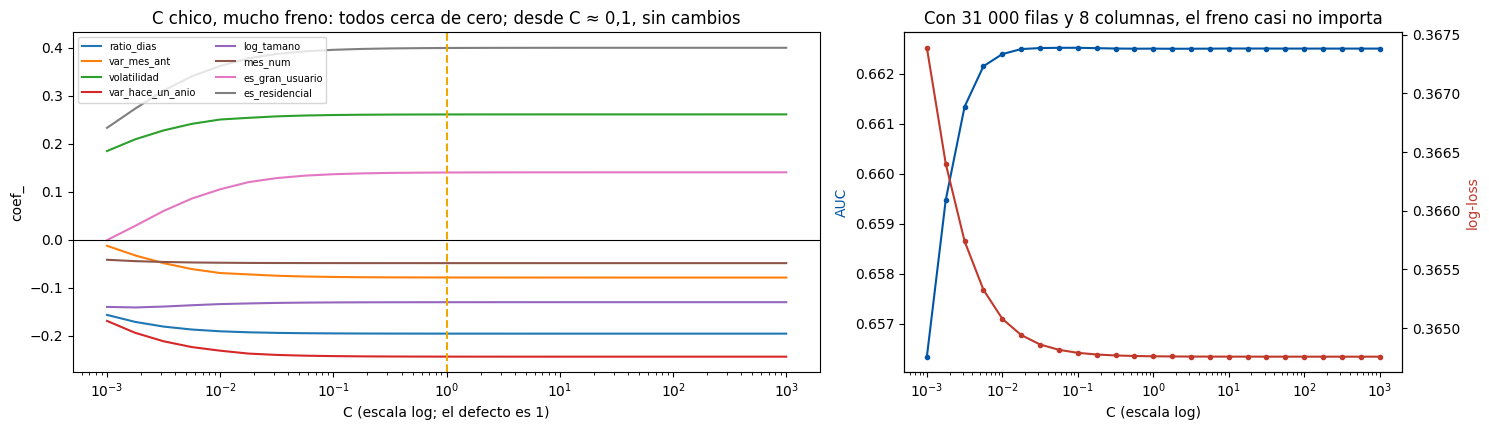

ℓ1 con C=0.01 deja en cero: ['var_mes_ant'] · el resto: {'ratio_dias': np.float64(-0.17), 'volatilidad': np.float64(0.18), 'var_hace_un_anio': np.float64(-0.2), 'log_tamano': np.float64(-0.14), 'mes_num': np.float64(-0.03), 'es_gran_usuario': np.float64(0.0), 'es_residencial': np.float64(0.26)}


In [14]:
Cs = np.logspace(-3, 3, 25)
caminos_C, auc_C, ll_C = [], [], []
for C in Cs:
    m = preparado(LogisticRegression(C=C)).fit(X_ent, y_ent)
    caminos_C.append(m[-1].coef_[0]); p = m.predict_proba(X_pru)[:, 1]; auc_C.append(roc_auc_score(y_pru, p)); ll_C.append(log_loss(y_pru, p))
caminos_C = pd.DataFrame(caminos_C, index=Cs, columns=PREDICTORAS)

fig, (a, b) = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [3, 2]})
for col in PREDICTORAS: a.plot(Cs, caminos_C[col], lw=1.5, label=col)
a.set_xscale("log"); a.axhline(0, color="black", lw=0.8); a.axvline(1, color=AMBAR, ls="--", lw=1.5); a.set_xlabel("C (escala log; el defecto es 1)"); a.set_ylabel("coef_"); a.legend(fontsize=7, ncol=2)
a.set_title("C chico, mucho freno: todos cerca de cero; desde C ≈ 0,1, sin cambios")
b.plot(Cs, auc_C, marker="o", ms=3, color=AZUL); b.set_xscale("log"); b.set_xlabel("C (escala log)"); b.set_ylabel("AUC", color=AZUL)
b2 = b.twinx(); b2.plot(Cs, ll_C, marker="o", ms=3, color=ROJO); b2.set_ylabel("log-loss", color=ROJO)
b.set_title("Con 31 000 filas y 8 columnas, el freno casi no importa")
plt.tight_layout(); plt.show()
registrar("logística C=0.001", preparado(LogisticRegression(C=0.001)))
registrar("logística C=100", preparado(LogisticRegression(C=100)))
registrar("logística ℓ1, C=0.01", preparado(LogisticRegression(l1_ratio=1.0, C=0.01, solver="liblinear")))
l1 = resultados["logística ℓ1, C=0.01"]["modelo"][-1].coef_[0]
print("ℓ1 con C=0.01 deja en cero:", [col for col, v in zip(PREDICTORAS, l1) if v == 0], "· el resto:", {col: round(v, 2) for col, v in zip(PREDICTORAS, l1) if v != 0})

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con muchas más filas que columnas, la regularización por defecto no cambia nada: los coeficientes son los mismos de C = 0,1 en adelante. ℓ1 con freno fuerte elige: deja en cero <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">var_mes_ant</code> (se queda con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code>, su pareja correlacionada) y deja a <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_gran_usuario</code> casi en cero, sin perder AUC.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.4 · Sin ecuación normal: el gradiente, a mano</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El gradiente del log-loss, (1/m) Xᵀ(σ(Xθ) − y), en un bucle, contra la biblioteca sin freno (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">C=np.inf</code>).</p></div>

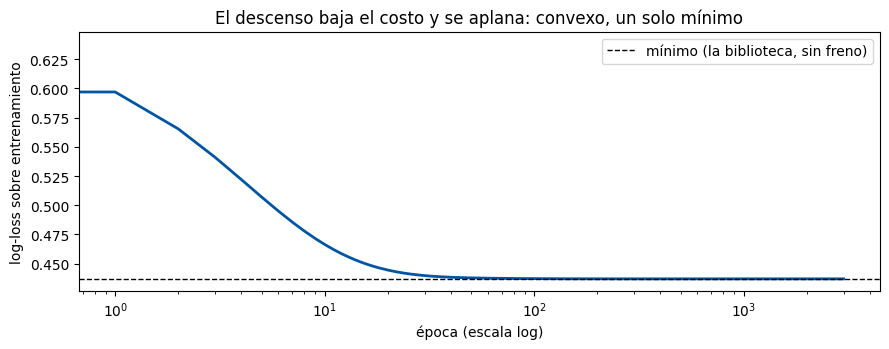

,gradiente a mano (3000 épocas),LogisticRegression(C=np.inf),"LogisticRegression() (ℓ2, C=1)"
sesgo,-1.671,-1.671,-1.671
ratio_dias,-0.196,-0.196,-0.196
var_mes_ant,-0.079,-0.079,-0.079
volatilidad,0.261,0.261,0.261
var_hace_un_anio,-0.244,-0.244,-0.244
log_tamano,-0.130,-0.130,-0.130
mes_num,-0.049,-0.049,-0.049
es_gran_usuario,0.141,0.141,0.140
es_residencial,0.401,0.400,0.400


In [15]:
X_ent_esc = modelo[:-1].transform(X_ent)
X_b = np.c_[np.ones(len(X_ent_esc)), X_ent_esc]
y_np = y_ent.to_numpy()
def log_loss_de(theta): p = sigmoide(X_b @ theta); return -np.mean(y_np * np.log(p) + (1 - y_np) * np.log(1 - p))
theta = np.zeros(X_b.shape[1]); historia = []
for epoca in range(3000):
    grad = X_b.T @ (sigmoide(X_b @ theta) - y_np) / len(y_np)
    theta = theta - 0.5 * grad
    historia.append(log_loss_de(theta))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sin_freno = preparado(LogisticRegression(C=np.inf)).fit(X_ent, y_ent)
comparacion = pd.DataFrame({"gradiente a mano (3000 épocas)": theta, "LogisticRegression(C=np.inf)": np.r_[sin_freno[-1].intercept_, sin_freno[-1].coef_[0]],
                            "LogisticRegression() (ℓ2, C=1)": np.r_[logistica.intercept_, logistica.coef_[0]]}, index=["sesgo"] + PREDICTORAS)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(historia, color=AZUL, lw=2); ax.axhline(log_loss_de(comparacion.iloc[:, 1].to_numpy()), color="black", ls="--", lw=1, label="mínimo (la biblioteca, sin freno)")
ax.set_xscale("log"); ax.set_xlabel("época (escala log)"); ax.set_ylabel("log-loss sobre entrenamiento"); ax.legend(); ax.set_title("El descenso baja el costo y se aplana: convexo, un solo mínimo")
plt.tight_layout(); plt.show()
comparacion.round(3)

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.5 · El desbalance: pesar las clases</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">class_weight="balanced"</code> pesa cada caída como ~5 filas normales. Se compara con bajar el umbral.</p></div>

In [16]:
balanceada = registrar("logística class_weight=balanced", preparado(LogisticRegression(class_weight="balanced")))
registrar(f"logística C=1, umbral {UMBRAL_ALT}", preparado(LogisticRegression()), umbral=UMBRAL_ALT)
for k in ["logística (escalada, C=1)", f"logística C=1, umbral {UMBRAL_ALT}", "logística class_weight=balanced"]:
    r = resultados[k]; print(f"{k:36s} precisión {r['precisión']:.3f} · exhaustividad {r['exhaustividad']:.3f} · F1 {r['F1']:.3f} · AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f}")
print(f"sesgo: C=1 → {logistica.intercept_[0]:.2f} (p̂ promedio {sigmoide(logistica.intercept_[0]):.3f}) · balanced → {balanceada[-1].intercept_[0]:.2f} (p̂ promedio {sigmoide(balanceada[-1].intercept_[0]):.3f})")

logística (escalada, C=1)            precisión 0.556 · exhaustividad 0.013 · F1 0.026 · AUC 0.663 · log-loss 0.365
logística C=1, umbral 0.15           precisión 0.216 · exhaustividad 0.520 · F1 0.306 · AUC 0.663 · log-loss 0.365
logística class_weight=balanced      precisión 0.249 · exhaustividad 0.403 · F1 0.308 · AUC 0.661 · log-loss 0.578
sesgo: C=1 → -1.67 (p̂ promedio 0.158) · balanced → -0.10 (p̂ promedio 0.476)


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las dos estrategias hacen lo mismo por caminos distintos: atrapan más caídas a cambio de más falsas alarmas, con el mismo AUC (el orden de las filas casi no cambia). La diferencia está en el log-loss: balanced empuja todas las probabilidades hacia arriba a propósito, y dejan de ser probabilidades calibradas. Bajar el umbral conserva las probabilidades honestas y mueve solo la decisión.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.6 · Softmax: tres clases</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Primero, la figura de la diapositiva con iris, igual que en la cátedra. Después, softmax sobre nuestros datos: <b>baja</b> (cae más de 5 %), <b>estable</b> (±5 %) o <b>sube</b> (más de 5 %).</p></div>

coef_ tiene forma (3, 2): un vector por clase · intercept_ [ 18.91   6.4  -25.31] · clases [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,petal length (cm),petal width (cm),p̂(setosa),p̂(versicolor),p̂(virginica),predict
0,1.5,0.3,0.995,0.005,0.000,setosa
1,4.5,1.4,0.000,0.963,0.036,versicolor
2,5.5,2.0,0.000,0.007,0.993,virginica


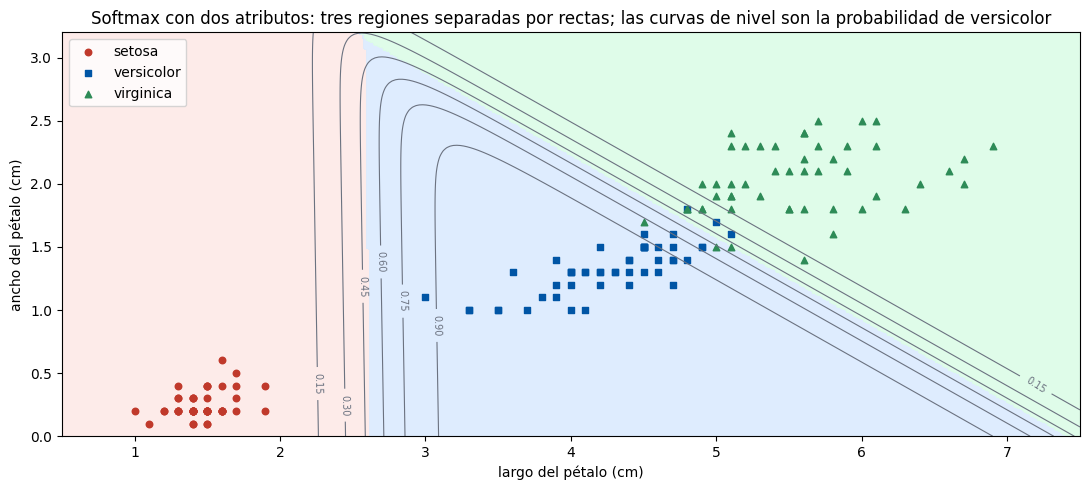

Actividad de la diapositiva: puntajes [2. 1. 0.] → softmax = [0.665 0.245 0.09 ] (suman 1); gana la clase 1 con 66.5 %
Entropía cruzada de la softmax sobre las 150 flores (promedio de −log p̂ de la clase correcta): 0.079


In [17]:
softmax = LogisticRegression(C=10).fit(dos, flores["target"])                   # y con 3 clases: softmax automático
print(f"coef_ tiene forma {softmax.coef_.shape}: un vector por clase · intercept_ {softmax.intercept_.round(2)} · clases {list(iris.target_names)}")
nuevas = pd.DataFrame({"petal length (cm)": [1.5, 4.5, 5.5], "petal width (cm)": [0.3, 1.4, 2.0]})
tabla_sm = nuevas.copy()
tabla_sm[[f"p̂({n})" for n in iris.target_names]] = softmax.predict_proba(nuevas).round(3)      # tres columnas que suman 1
tabla_sm["predict"] = [iris.target_names[k] for k in softmax.predict(nuevas)]                    # la clase de mayor probabilidad
display(tabla_sm)

g1, g2 = np.meshgrid(np.linspace(0.5, 7.5, 300), np.linspace(0, 3.2, 300))
grilla = pd.DataFrame({"petal length (cm)": g1.ravel(), "petal width (cm)": g2.ravel()})
clase = softmax.predict(grilla).reshape(g1.shape); p_versicolor = softmax.predict_proba(grilla)[:, 1].reshape(g1.shape)
fig, ax = plt.subplots(figsize=(11, 5))
ax.contourf(g1, g2, clase, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#fde9e7", "#dbeafe", "#dcfce7"], alpha=0.9)
cs = ax.contour(g1, g2, p_versicolor, levels=[0.15, 0.3, 0.45, 0.6, 0.75, 0.9], colors=[GRIS], linewidths=0.8); ax.clabel(cs, fmt="%.2f", fontsize=7)
for k, (nombre, marca, color) in enumerate(zip(iris.target_names, ["o", "s", "^"], [ROJO, AZUL, VERDE])):
    ax.scatter(dos.loc[flores["target"] == k, "petal length (cm)"], dos.loc[flores["target"] == k, "petal width (cm)"], marker=marca, color=color, s=22, label=nombre)
ax.set_xlabel("largo del pétalo (cm)"); ax.set_ylabel("ancho del pétalo (cm)"); ax.legend(loc="upper left")
ax.set_title("Softmax con dos atributos: tres regiones separadas por rectas; las curvas de nivel son la probabilidad de versicolor")
plt.tight_layout(); plt.show()
puntajes = np.array([2.0, 1.0, 0.0]); probas = np.exp(puntajes) / np.exp(puntajes).sum()
print(f"Actividad de la diapositiva: puntajes {puntajes} → softmax = {probas.round(3)} (suman {probas.sum():.0f}); gana la clase 1 con {probas[0] * 100:.1f} %")
print(f"Entropía cruzada de la softmax sobre las 150 flores (promedio de −log p̂ de la clase correcta): {log_loss(flores['target'], softmax.predict_proba(dos)):.3f}")

Proporción de cada clase (entrenamiento): {'baja': 36.1, 'estable': 29.7, 'sube': 34.2}
coef_ tiene forma (3, 8): un vector de 8 pesos por clase
exactitud softmax = 0.477  ·  siempre «baja» = 0.315
entropía cruzada softmax = 1.039  ·  proporciones constantes = 1.103


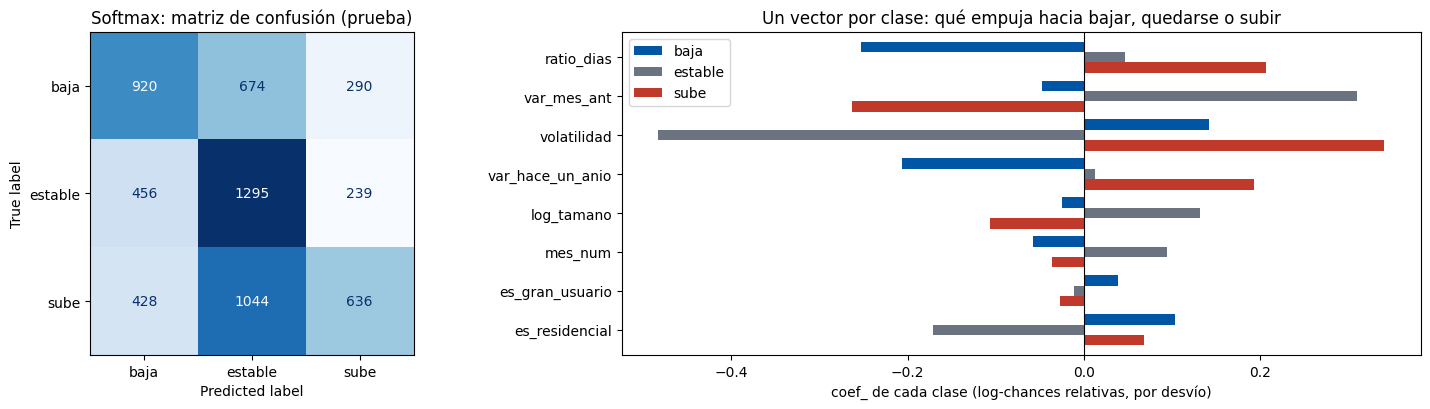

In [18]:
datos["direccion"] = np.select([datos["demanda_MWh"] < 0.95 * datos["lag1"], datos["demanda_MWh"] > 1.05 * datos["lag1"]], [0, 2], 1)
CLASES = ["baja", "estable", "sube"]
d_ent, d_pru = datos.loc[ent_mask, "direccion"], datos.loc[~ent_mask, "direccion"]
print("Proporción de cada clase (entrenamiento):", (d_ent.value_counts(normalize=True).sort_index() * 100).round(1).set_axis(CLASES).to_dict())

softmax_cammesa = preparado(LogisticRegression()).fit(X_ent, d_ent)               # tres clases: softmax automático
p3 = softmax_cammesa.predict_proba(X_pru)
print(f"coef_ tiene forma {softmax_cammesa[-1].coef_.shape}: un vector de 8 pesos por clase")
mayoritaria = d_ent.value_counts().idxmax()
print(f"exactitud softmax = {accuracy_score(d_pru, softmax_cammesa.predict(X_pru)):.3f}  ·  siempre «{CLASES[mayoritaria]}» = {accuracy_score(d_pru, np.full(len(d_pru), mayoritaria)):.3f}")
print(f"entropía cruzada softmax = {log_loss(d_pru, p3):.3f}  ·  proporciones constantes = {log_loss(d_pru, np.tile(d_ent.value_counts(normalize=True).sort_index().to_numpy(), (len(d_pru), 1))):.3f}")

fig, (a, b) = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.1, 1.6]})
ConfusionMatrixDisplay(confusion_matrix(d_pru, softmax_cammesa.predict(X_pru)), display_labels=CLASES).plot(ax=a, colorbar=False, cmap="Blues"); a.set_title("Softmax: matriz de confusión (prueba)")
coef3 = pd.DataFrame(softmax_cammesa[-1].coef_, index=CLASES, columns=PREDICTORAS)
coef3.T.plot.barh(ax=b, color=[AZUL, GRIS, ROJO], width=0.8); b.axvline(0, color="black", lw=0.8); b.invert_yaxis()
b.set_xlabel("coef_ de cada clase (log-chances relativas, por desvío)"); b.set_title("Un vector por clase: qué empuja hacia bajar, quedarse o subir")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las tres clases están balanceadas (un tercio cada una), así que decir siempre la clase más frecuente del entrenamiento da ~32 % de exactitud en prueba. Softmax llega a ~48 %, y su entropía cruzada mejora la de las proporciones constantes: mejor, pero lejos de resolverlo. La matriz muestra el sesgo: tiende a decir «estable» cuando duda. Los coeficientes se leen de a pares y tienen sentido: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code> alto empuja hacia «sube» y en contra de «baja»; la volatilidad empuja hacia los dos extremos (baja y sube) y en contra de «estable», que es justamente lo que una sola logística binaria no podía decir con un solo coeficiente.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">6 · El comparativo: cuál resultó mejor, y cómo se elige</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La matriz, y por qué una sola métrica no alcanza</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">AUC: cuán bien ordena por riesgo, sin umbral. Log-loss: cuán buenas son las probabilidades. Precisión y exhaustividad: dependen del umbral. La exactitud es la que menos dice.</p></div>

In [19]:
METRICAS = ["exactitud", "precisión", "exhaustividad", "F1", "AUC", "log-loss", "ajuste (ms)"]
matriz = pd.DataFrame({k: {m: v[m] for m in METRICAS} for k, v in resultados.items()}).T.astype(float)
(matriz.style.format({m: "{:.3f}" for m in METRICAS[:6]}).format({"ajuste (ms)": "{:.1f}"})
       .background_gradient(subset=["exactitud", "precisión", "exhaustividad", "F1", "AUC"], cmap="RdYlGn")
       .background_gradient(subset=["log-loss", "ajuste (ms)"], cmap="RdYlGn_r"))

,exactitud,precisión,exhaustividad,F1,AUC,log-loss,ajuste (ms)
línea de base (mayoritaria),0.873119,0.000000,0.000000,0.000000,0.500000,4.573242,2.2
"logística (escalada, C=1)",0.873454,0.555556,0.013175,0.025740,0.662507,0.364760,75.9
"logística relativas, sin escalar",0.873454,0.555556,0.013175,0.025740,0.662233,0.364926,196.2
"logística con lag1 en MWh, sin escalar",0.872785,0.333333,0.002635,0.005229,0.555630,0.379781,285.0
"logística con lag1 en MWh, sin escalar, 5000 iter.",0.872952,0.470588,0.010540,0.020619,0.657600,0.366408,2971.4
"logística relativas, escaladas",0.873454,0.555556,0.013175,0.025740,0.662507,0.364760,54.7
logística C=0.001,0.873119,0.500000,0.006588,0.013004,0.656338,0.367389,49.3
logística C=100,0.873454,0.555556,0.013175,0.025740,0.662508,0.364757,54.2
"logística ℓ1, C=0.01",0.873287,0.533333,0.010540,0.020672,0.657240,0.367630,72.4
logística class_weight=balanced,0.769809,0.248780,0.403162,0.307692,0.661421,0.578372,82.3


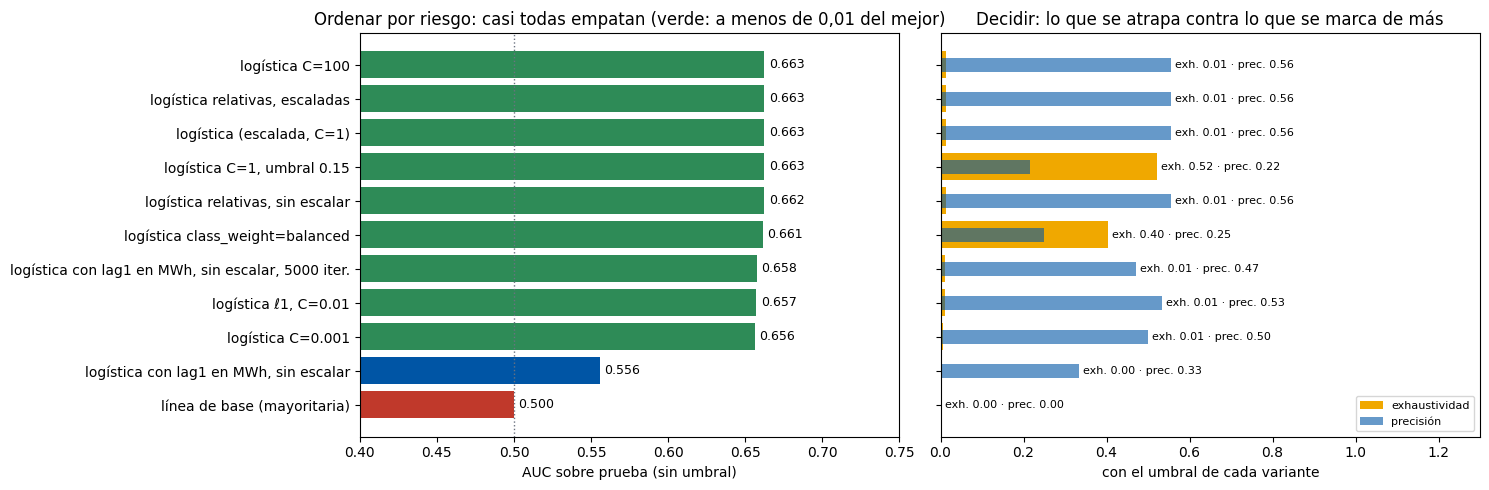

In [20]:
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
orden = matriz.sort_values("AUC", ascending=False)
mejor_auc = orden["AUC"].max()
a.barh(orden.index, orden["AUC"], color=[VERDE if v >= mejor_auc - 0.01 else (ROJO if v < 0.55 else AZUL) for v in orden["AUC"]]); a.invert_yaxis(); a.set_xlim(0.4, 0.75)
for k, v in enumerate(orden["AUC"]): a.text(v + 0.003, k, f"{v:.3f}", va="center", fontsize=9)
a.axvline(0.5, color=GRIS, ls=":", lw=1); a.set_xlabel("AUC sobre prueba (sin umbral)"); a.set_title("Ordenar por riesgo: casi todas empatan (verde: a menos de 0,01 del mejor)")
b.barh(orden.index, orden["exhaustividad"], color=AMBAR, label="exhaustividad"); b.barh(orden.index, orden["precisión"], color=AZUL, alpha=0.6, height=0.4, label="precisión")
for k, (e, p) in enumerate(zip(orden["exhaustividad"], orden["precisión"])): b.text(max(e, p) + 0.01, k, f"exh. {e:.2f} · prec. {p:.2f}", va="center", fontsize=8)
b.set_xlim(0, 1.3); b.set_xlabel("con el umbral de cada variante"); b.legend(loc="lower right", fontsize=8); b.set_title("Decidir: lo que se atrapa contra lo que se marca de más")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La elección</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">El ordenador</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La logística escalada con C = 1: AUC de ~0,66, probabilidades calibradas (mejor log-loss que la probabilidad constante) y coeficientes con sentido. Las variantes con otro C o ℓ1 empatan; la de lag1 en MWh sin escalar queda atrás.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La decisión</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">El umbral se fija aparte: con 0,5 el modelo no sirve; con 0,15 (elegido en validación) atrapa cerca de la mitad de las caídas con mucha falsa alarma. Si se acepta ese precio lo decide quien usa el modelo.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que no se elige</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">balanced: es otra forma de bajar el umbral, pagando con probabilidades corridas.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que queda claro</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">El límite no está en el ajuste: está en la información. Ocho señales débiles sumadas linealmente dan un AUC de 0,66. Mejorarlo pide otras predictoras o un modelo que combine las columnas de forma no lineal.</td></tr></table></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">7 · Usarlo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Dos agentes nuevos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Inventados para la demostración: una distribuidora residencial grande y estable, prediciendo marzo (31 días después de febrero); y un gran usuario chico que el mes pasado subió un 60 %, prediciendo febrero y sin dato del año anterior.</p></div>

In [21]:
final = resultados["logística (escalada, C=1)"]["modelo"]
nuevo = pd.DataFrame([
    {"ratio_dias": 31 / 28, "var_mes_ant": 0.02, "volatilidad": 0.02, "var_hace_un_anio": 0.08, "log_tamano": np.log10(80000), "mes_num": 3, "es_gran_usuario": 0, "es_residencial": 1},
    {"ratio_dias": 28 / 31, "var_mes_ant": 0.60, "volatilidad": 0.60, "var_hace_un_anio": np.nan, "log_tamano": np.log10(150), "mes_num": 2, "es_gran_usuario": 1, "es_residencial": 0},
], index=["distribuidora grande · marzo", "gran usuario chico · febrero"])
nuevo["p̂(cae fuerte)"] = final.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo["predict (0,5)"] = final.predict(nuevo[PREDICTORAS])
nuevo[f"decisión con {UMBRAL_ALT}"] = (nuevo["p̂(cae fuerte)"] >= UMBRAL_ALT).astype(int)
nuevo

,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,p̂(cae fuerte),"predict (0,5)",decisión con 0.15
distribuidora grande · marzo,1.107143,0.02,0.02,0.08,4.903090,3,0,1,0.110,0,0
gran usuario chico · febrero,0.903226,0.60,0.60,NaN,2.176091,2,1,0,0.243,0,1


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Diez filas, con su probabilidad explicada</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Diez filas de prueba de menor a mayor probabilidad: datos, puntaje, probabilidad, decisión con el umbral elegido, lo real; los aportes en log-chances; y la oración de cada una.</p></div>

In [22]:
orden_prob = np.argsort(prob)
elegidos = orden_prob[np.linspace(0, len(orden_prob) - 1, 10).astype(int)]
Z10 = X_pru_esc[elegidos]
aportes = pd.DataFrame(logistica.coef_[0] * Z10, columns=PREDICTORAS, index=X_pru.index[elegidos])
explicado = X_pru.iloc[elegidos].copy()
explicado.insert(0, "serie", datos.loc[X_pru.index[elegidos], "serie"].str.slice(0, 34))
explicado["puntaje"] = (logistica.intercept_[0] + aportes.sum(axis=1)).round(2)
explicado["p̂(cae)"] = sigmoide(explicado["puntaje"]).round(3)
explicado["decisión"] = (explicado["p̂(cae)"] >= UMBRAL_ALT).astype(int)
explicado["real"] = y_pru.iloc[elegidos].values
explicado["acierta"] = np.where(explicado["decisión"] == explicado["real"], "sí", "no")
explicado.index.name = "fila"
(explicado.style.format(precision=2)
    .background_gradient(subset=["p̂(cae)"], cmap="RdYlGn_r", vmin=0, vmax=0.5)
    .apply(lambda s: ["background-color: #dcfce7" if v == "sí" else "background-color: #fde9e7" for v in s], subset=["acierta"])
    .set_caption(f"Diez filas de prueba de menor a mayor p̂: datos, puntaje, probabilidad, decisión con umbral {UMBRAL_ALT}, real, y si acertó"))

,serie,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,puntaje,p̂(cae),decisión,real,acierta
fila,,,,,,,,,,,,,,
35233,AYSAVAOY | GUMAS/AUTOGENERADORES,1.03,-0.01,0.01,3.00,3.21,12,1,0,-4.98,0.01,0,0,sí
33886,CMOREN1W | TARIFA USUARIO NO RESID,1.03,0.11,0.11,0.02,2.74,10,0,0,-2.37,0.09,0,0,sí
35385,CNEGOL3Y | GUMAS/AUTOGENERADORES,1.03,0.02,0.02,-0.04,3.54,12,1,0,-2.20,0.10,0,0,sí
35690,LOMAZAQY | GUMAS/AUTOGENERADORES,1.03,-0.08,0.08,-0.09,3.48,12,1,0,-2.09,0.11,0,0,sí
35129,VWARGPOY | GUMAS/AUTOGENERADORES,0.97,0.07,0.07,0.04,3.56,11,1,0,-1.99,0.12,0,0,sí
34488,AYSASAOY | GUMAS/AUTOGENERADORES,0.97,0.03,0.03,-0.03,3.13,11,1,0,-1.90,0.13,0,0,sí
34870,EPESAFSD | RESIDENCIAL,0.97,-0.02,0.02,0.11,5.48,11,0,1,-1.78,0.14,0,0,sí
37279,REFRLOOY | GUMAS/AUTOGENERADORES,0.94,-0.04,0.04,-0.13,3.70,2,1,0,-1.59,0.17,1,0,no
32956,APELPALD | RESIDENCIAL,0.97,-0.04,0.04,-0.18,4.46,9,0,1,-1.34,0.21,1,0,no


In [23]:
tabla_aportes = aportes.copy()
tabla_aportes.insert(0, "sesgo", logistica.intercept_[0])
tabla_aportes["puntaje"] = tabla_aportes.sum(axis=1)
tabla_aportes["p̂"] = sigmoide(tabla_aportes["puntaje"])
tabla_aportes.index.name = "fila"
lim_ap = np.abs(aportes.to_numpy()).max()
(tabla_aportes.style.format("{:+.2f}").format("{:.2f}", subset=["sesgo", "puntaje"]).format("{:.3f}", subset=["p̂"])
    .background_gradient(subset=PREDICTORAS, cmap="RdBu_r", vmin=-lim_ap, vmax=lim_ap)
    .set_caption("Cómo se arma cada puntaje: sesgo + un aporte por columna (rojo empuja a la caída, azul la aleja), en log-chances; después, σ(puntaje) = p̂"))

,sesgo,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,puntaje,p̂
fila,,,,,,,,,,,
35233,-1.67,-0.12,+0.01,-0.13,-2.77,-0.03,-0.08,+0.16,-0.35,-4.98,0.007
33886,-1.67,-0.12,-0.01,-0.07,-0.00,+0.03,-0.06,-0.13,-0.35,-2.37,0.086
35385,-1.67,-0.12,+0.01,-0.13,+0.06,-0.07,-0.08,+0.16,-0.35,-2.20,0.100
35690,-1.67,-0.12,+0.02,-0.09,+0.10,-0.06,-0.08,+0.16,-0.35,-2.09,0.110
35129,-1.67,+0.12,-0.00,-0.09,-0.02,-0.07,-0.07,+0.16,-0.35,-1.99,0.120
34488,-1.67,+0.12,+0.00,-0.12,+0.04,-0.02,-0.07,+0.16,-0.35,-1.90,0.130
34870,-1.67,+0.12,+0.01,-0.13,-0.08,-0.30,-0.07,-0.13,+0.46,-1.78,0.145
37279,-1.67,+0.25,+0.02,-0.11,+0.14,-0.09,+0.06,+0.16,-0.35,-1.59,0.169
32956,-1.67,+0.12,+0.02,-0.11,+0.18,-0.18,-0.04,-0.13,+0.46,-1.34,0.207


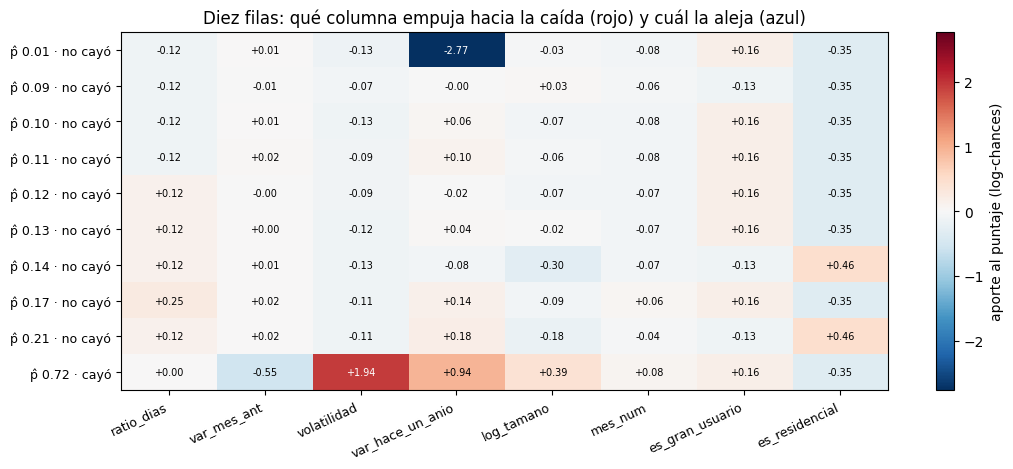

In [24]:
fig, ax = plt.subplots(figsize=(11, 4.8))
im = ax.imshow(aportes.to_numpy(), cmap="RdBu_r", vmin=-lim_ap, vmax=lim_ap, aspect="auto")
ax.set_xticks(range(len(PREDICTORAS))); ax.set_xticklabels(PREDICTORAS, rotation=25, ha="right", fontsize=9)
ax.set_yticks(range(len(elegidos))); ax.set_yticklabels([f"p̂ {p:.2f} · {'cayó' if r == 1 else 'no cayó'}" for p, r in zip(explicado["p̂(cae)"], explicado["real"])], fontsize=9)
for r in range(aportes.shape[0]):
    for cidx in range(aportes.shape[1]):
        v = aportes.iloc[r, cidx]; ax.text(cidx, r, f"{v:+.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > lim_ap / 2 else "black")
plt.colorbar(im, ax=ax, label="aporte al puntaje (log-chances)")
ax.set_title("Diez filas: qué columna empuja hacia la caída (rojo) y cuál la aleja (azul)")
plt.tight_layout(); plt.show()

In [25]:
medias = pd.Series(modelo[1].mean_, index=PREDICTORAS)          # la fila promedio (después de imputar): el cero de cada columna
def fmt(col, v):
    if pd.isna(v): return "faltante, imputado"
    if col == "log_tamano": return f"{10 ** v:,.0f} MWh el mes anterior".replace(",", ".")
    if col in ("var_mes_ant", "var_hace_un_anio", "volatilidad"): return f"{v * 100:+.0f} %" if col != "volatilidad" else f"{v * 100:.0f} %"
    if col == "ratio_dias": return f"{v:.3f}"
    return f"{v:.0f}"
for fila_id in aportes.index:
    fila = explicado.loc[fila_id]; ap = aportes.loc[fila_id]
    partes = []
    for col in ap.abs().sort_values(ascending=False).index[:2]:
        lado = "por encima" if Z10[list(aportes.index).index(fila_id), PREDICTORAS.index(col)] > 0 else "por debajo"
        empuje = "hacia la caída" if ap[col] > 0 else "en contra"
        partes.append(f"{ap[col]:+.2f} por {col} ({fmt(col, X_pru.loc[fila_id, col])}, {lado} del promedio: {empuje})")
    real = "cayó" if fila["real"] == 1 else "no cayó"
    print(f"{fila['serie']}: p̂ = {fila['p̂(cae)']:.3f} → {'alarma' if fila['decisión'] == 1 else 'sin alarma'}; real: {real} ({'acierto' if fila['acierta'] == 'sí' else 'error'}). "
          f"Parte de {logistica.intercept_[0]:.2f}; " + "; ".join(partes) + f". Puntaje {fila['puntaje']:.2f}.")

AYSAVAOY | GUMAS/AUTOGENERADORES: p̂ = 0.007 → sin alarma; real: no cayó (acierto). Parte de -1.67; -2.77 por var_hace_un_anio (+300 %, por encima del promedio: en contra); -0.35 por es_residencial (0, por debajo del promedio: en contra). Puntaje -4.98.
CMOREN1W | TARIFA USUARIO NO RESID: p̂ = 0.085 → sin alarma; real: no cayó (acierto). Parte de -1.67; -0.35 por es_residencial (0, por debajo del promedio: en contra); -0.13 por es_gran_usuario (0, por debajo del promedio: en contra). Puntaje -2.37.
CNEGOL3Y | GUMAS/AUTOGENERADORES: p̂ = 0.100 → sin alarma; real: no cayó (acierto). Parte de -1.67; -0.35 por es_residencial (0, por debajo del promedio: en contra); +0.16 por es_gran_usuario (1, por encima del promedio: hacia la caída). Puntaje -2.20.
LOMAZAQY | GUMAS/AUTOGENERADORES: p̂ = 0.110 → sin alarma; real: no cayó (acierto). Parte de -1.67; -0.35 por es_residencial (0, por debajo del promedio: en contra); +0.16 por es_gran_usuario (1, por encima del promedio: hacia la caída). Punta

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La misma predicción, en una aplicación</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se guarda el modelo elegido con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">joblib</code> y el umbral elegido en validación en un archivo aparte. La app pide la historia del agente (mes anterior, dos meses antes, el mismo mes y el anterior del año pasado), calcula las ocho predictoras igual que el cuaderno, y muestra la probabilidad, la decisión con un umbral deslizante y los aportes. Está armada para que los cuadernos de las clases siguientes puedan sumar sus modelos a la comparación.</p></div>

In [26]:
import joblib, json

joblib.dump(final, "modelo_cammesa_32.joblib")
with open("umbral_cammesa_32.json", "w", encoding="utf-8") as f:
    json.dump({"umbral": UMBRAL_ALT, "umbral_caida": UMBRAL_CAIDA}, f)
cargado = joblib.load("modelo_cammesa_32.joblib")
print("Guardados: modelo_cammesa_32.joblib y umbral_cammesa_32.json")
print("Mismas probabilidades tras guardar y cargar:", np.allclose(cargado.predict_proba(X_pru), final.predict_proba(X_pru)))

Guardados: modelo_cammesa_32.joblib y umbral_cammesa_32.json
Mismas probabilidades tras guardar y cargar: True


In [27]:
%%writefile app_cammesa_32.py
# Clase 32 sobre CAMMESA · regresión logística · aplicación Streamlit
# Para abrirla, desde la carpeta del cuaderno:  streamlit run app_cammesa_32.py
import calendar
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

PREDICTORAS = ["ratio_dias", "var_mes_ant", "volatilidad", "var_hace_un_anio", "log_tamano", "mes_num", "es_gran_usuario", "es_residencial"]
AZUL, ROJO = "#0055a5", "#c0392b"
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

st.set_page_config(page_title="¿Va a caer fuerte la demanda?", layout="centered")
st.title("¿La demanda de este agente va a caer fuerte?")

# ---------- 1 · Los modelos guardados por los cuadernos ----------
MODELOS = {
    "regresión logística": ("modelo_cammesa_32.joblib", "Clase_32_regresion_logistica_y_softmax_CAMMESA.ipynb"),
}
PROPIOS = ["regresión logística"]

@st.cache_resource
def cargar(archivo):
    return joblib.load(archivo)

modelos = {}
for nombre, (archivo, cuaderno) in MODELOS.items():
    if Path(archivo).exists():
        modelos[nombre] = cargar(archivo)
    elif nombre in PROPIOS:
        st.error(f"Falta {archivo}. Ejecutar antes el cuaderno {cuaderno}, que lo genera."); st.stop()
    else:
        st.warning(f"Falta {archivo} (lo genera {cuaderno}): la comparación se muestra sin {nombre}.")

config = json.loads(Path("umbral_cammesa_32.json").read_text(encoding="utf-8")) if Path("umbral_cammesa_32.json").exists() else {"umbral": 0.15, "umbral_caida": 0.15}
st.caption(f"«Caer fuerte» = demanda del mes menor al {100 - config['umbral_caida'] * 100:.0f} % de la del mes anterior. Regresión logística de la clase 32 sobre demanda-ltimos-aos.csv.")

# ---------- 2 · La historia del agente ----------
st.subheader("Historia del agente")
c1, c2 = st.columns(2)
lag1 = c1.number_input("Demanda del mes anterior (MWh)", 1.0, 1_600_000.0, 5_000.0, step=100.0)
lag2 = c1.number_input("Demanda de hace dos meses (MWh)", 0.0, 1_600_000.0, 4_800.0, step=100.0)
conoce_anio = c1.checkbox("Conozco el año pasado", value=True)
lag12 = c1.number_input("Hace un año: el mismo mes (MWh)", 0.0, 1_600_000.0, 5_200.0, step=100.0, disabled=not conoce_anio)
lag13 = c1.number_input("Hace un año: el mes anterior (MWh)", 0.0, 1_600_000.0, 5_000.0, step=100.0, disabled=not conoce_anio)
anio = c2.number_input("Año", 2017, 2030, 2020)
mes = MESES.index(c2.selectbox("Mes a predecir", MESES, index=1)) + 1
tipo = c2.radio("Tipo de agente", ["Distribuidor · residencial", "Distribuidor · no residencial", "Gran usuario"])
umbral = c2.slider("Umbral de decisión", 0.05, 0.60, float(config["umbral"]), step=0.01)

# Las ocho predictoras, calculadas igual que en el cuaderno
anio_ant, mes_ant = (anio - 1, 12) if mes == 1 else (anio, mes - 1)
var_mes_ant = float(np.clip(lag1 / lag2 - 1, -1, 3)) if lag2 > 0 else np.nan
var_anio = float(np.clip(lag12 / lag13 - 1, -1, 3)) if conoce_anio and lag13 > 0 else np.nan
fila = pd.DataFrame([{"ratio_dias": calendar.monthrange(anio, mes)[1] / calendar.monthrange(anio_ant, mes_ant)[1],
                      "var_mes_ant": var_mes_ant, "volatilidad": abs(var_mes_ant) if not np.isnan(var_mes_ant) else np.nan,
                      "var_hace_un_anio": var_anio, "log_tamano": np.log10(lag1), "mes_num": mes,
                      "es_gran_usuario": int(tipo == "Gran usuario"), "es_residencial": int(tipo == "Distribuidor · residencial")}])[PREDICTORAS]

# ---------- 3 · Probabilidad y decisión ----------
probs = {nombre: float(m.predict_proba(fila)[0, 1]) for nombre, m in modelos.items()}
st.subheader("Predicción")
for col, (nombre, p) in zip(st.columns(len(probs)), probs.items()):
    col.metric(nombre, f"{p * 100:.1f} %".replace(".", ","))
    col.markdown(f":{'red' if p >= umbral else 'blue'}[**{'alarma: puede caer fuerte' if p >= umbral else 'sin alarma'}**] con umbral {umbral:.2f}".replace(".", ","))
st.write("La probabilidad la da el modelo; la alarma sale de compararla con el umbral, y el umbral lo decide quien usa el modelo.")

# ---------- 4 · Por qué ----------
if "regresión logística" in modelos:
    m = modelos["regresión logística"]
    z = m[:-1].transform(fila)[0]                       # imputado y escalado: 0 es la fila promedio
    logistica = m[-1]; aportes = logistica.coef_[0] * z
    puntaje = logistica.intercept_[0] + aportes.sum()
    st.subheader("Por qué")
    st.write(f"Parte de **{logistica.intercept_[0]:.2f}** log-chances y cada columna suma su coeficiente × su valor escalado. "
             f"Puntaje = **{puntaje:.2f}** → σ(puntaje) = **{1 / (1 + np.exp(-puntaje)):.3f}**.")
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.barh(PREDICTORAS, aportes, color=[ROJO if v > 0 else AZUL for v in aportes]); ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
    ax.set_xlabel("aporte a las log-chances (rojo: hacia la caída · azul: en contra)")
    plt.tight_layout(); st.pyplot(fig)

with st.expander("Ver la fila que recibe el modelo"):
    st.dataframe(fila)

Overwriting app_cammesa_32.py


<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Cómo abrirla</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit</code> instalado en <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">aa2026</code>: desde una terminal en la carpeta del cuaderno, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit run app_cammesa_32.py</code>.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Desde el cuaderno:</b> la celda siguiente la lanza sin consola; entrar a <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">http://localhost:8501</code> y, para cortarla, interrumpir el kernel (■).</p></div>

In [28]:
import sys
print("Abrir http://localhost:8502 en el navegador. Para cortarla: interrumpir el kernel (■).")
!"{sys.executable}" -m streamlit run app_cammesa_32.py --server.headless true

Abrir http://localhost:8502 en el navegador. Para cortarla: interrumpir el kernel (■).
^C


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">8 · Qué quedó</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>El problema se transformó:</b> de cuántos MWh a si la demanda cae más de un 15 %. Las predictoras pasaron a ser relativas (variaciones, volatilidad, log del tamaño, días del mes) porque lo que importa es el cambio, no el nivel.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>La logística es la recta pasada por la S:</b> el puntaje son log-chances, la salida una probabilidad, y la clase sale de un umbral. Con 17 % de caídas, el umbral de 0,5 no marca casi nada; el umbral se eligió en una validación temporal, no en la prueba.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Los coeficientes tienen sentido físico</b> (meses cortos, agentes chicos y volátiles, tarifas residenciales caen más), pero son todos débiles: razones de chances entre 0,8 y 1,5. El AUC de ~0,66 es el resultado honesto de un problema difícil.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Diferencias con la clase:</b> sin escalar converge igual porque las predictoras ya son relativas (con una columna en MWh, deja de converger); la regularización casi no importa con 31 000 filas y 8 columnas; y softmax se aplicó también a nuestros datos (baja / estable / sube), donde la volatilidad empuja a los dos extremos a la vez.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Qué sigue:</b> el límite está en la frontera lineal y en la información. Los modelos de las próximas clases pueden combinar las columnas de forma no lineal; la comparación con esta logística (guardada en <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">modelo_cammesa_32.joblib</code>) va a decir si vale la pena.</p></div>